# 1. Initial Step

In [ ]:
#Import important libraries
#core data handling 
import numpy as np
import pandas as pd 
#visualization
import matplotlib.pyplot as plt 
import seaborn as sns
#preprocessing vs model selection
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
#classification models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
#class imbalance handling 
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
#evaluration metrics
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay, precision_recall_curve, average_precision_score, f1_score, precision_score, recall_score
)

#unsupervised learning 
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
#reproducibility vs display settings
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 25)

# 1.1 Data loading and Initial Inspection

In [ ]:
#load the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

#view the first 10 rows of the dataset
#check the shape of the dataset
print(f"Dataset shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)


Dataset shape: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [ ]:
#Structural overview: data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
#check for duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")

#check for duplicated customer Ids
duplicated_customerids = df['customerID'].duplicated().sum()
print(f"Number of duplicated customer IDs: {duplicated_customerids}")

Number of duplicate rows: 0
Number of duplicated customer IDs: 0


There were no duplicated rows and no duplicated customer IDs founded

In [ ]:
#TotalCharges is object type, convert to numeric
total_charges_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
missing_mask = total_charges_numeric.isna()

print(f"Number of missing values in TotalCharges: {missing_mask.sum()}")
df.loc[missing_mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Number of missing values in TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


# 1.2 Data Cleaning

In [ ]:
#convert TotalCharges to numeric and fill missing values with 0
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

#standardise the target variable to a binary numeric
df['Churn_Flag'] = df['Churn'].map({'Yes': 1, 'No': 0})

#drop customerID
df_churn = df.drop(columns=['customerID'])

print(f"Remaining nulls:\n{df_churn.isnull().sum()} total null values")
df_churn[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Flag']].describe(include='all')

Remaining nulls:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
Churn_Flag          0
dtype: int64 total null values


,tenure,MonthlyCharges,TotalCharges,Churn,Churn_Flag
count,7043.000000,7043.000000,7043.000000,7043,7043.000000
unique,NaN,NaN,NaN,2,NaN
top,NaN,NaN,NaN,No,NaN
freq,NaN,NaN,NaN,5174,NaN
mean,32.371149,64.761692,2279.734304,NaN,0.265370
std,24.559481,30.090047,2266.794470,NaN,0.441561
min,0.000000,18.250000,0.000000,NaN,0.000000
25%,9.000000,35.500000,398.550000,NaN,0.000000
50%,29.000000,70.350000,1394.550000,NaN,0.000000
75%,55.000000,89.850000,3786.600000,NaN,1.000000


# 1.3 Exploratory Data Analysis

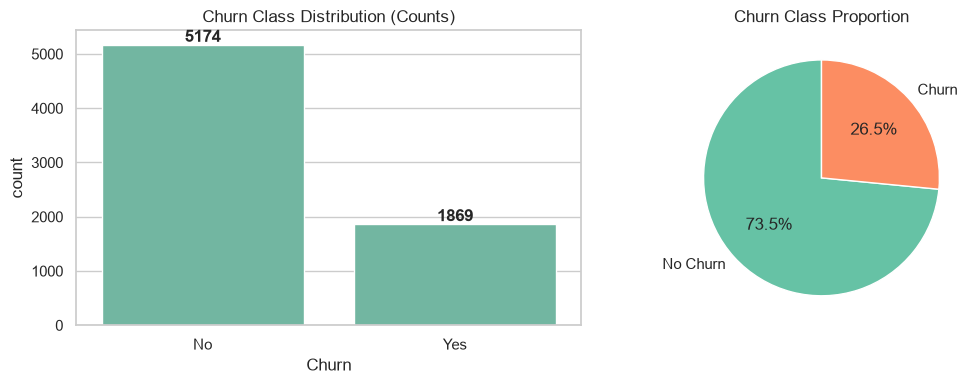

In [ ]:
#distribution of the target variable
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100

sns.countplot(data=df, x='Churn', ax=ax[0], order=['No', 'Yes'])
ax[0].set_title('Churn Class Distribution (Counts)')
for i, v in enumerate(churn_counts.reindex(['No', 'Yes'])):
    ax[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

#proportion of churn classes
ax[1].pie(churn_pct.reindex(['No', 'Yes']), labels=['No Churn', 'Churn'], autopct='%1.1f%%', colors=sns.color_palette("Set2")[:2], startangle=90)
ax[1].set_title('Churn Class Proportion')

plt.tight_layout()
plt.show()

The dataset is imbalanced, with only 26,5% of customers labelled as churned. If left unaddressed, a classifier could achieve 73.5% accuracy by trivially predicting "No churn" for every customer while providing zero business value.

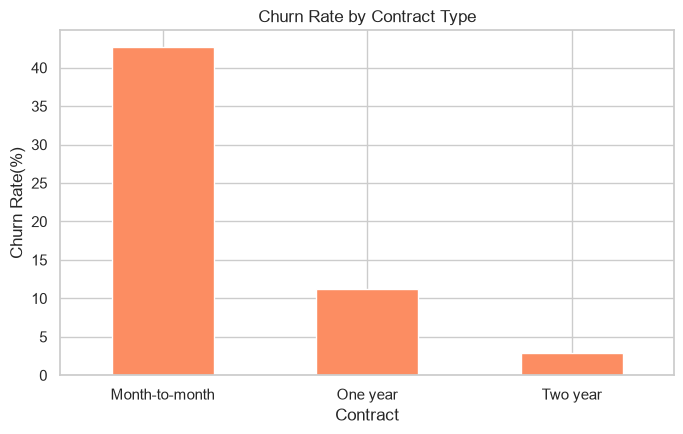

Churn             No   Yes
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


In [ ]:
#churn by contract type
plt.figure(figsize=(7, 4.5))
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn['Yes'].sort_values(ascending=False).plot(kind='bar', color=sns.color_palette("Set2")[1])
plt.ylabel('Churn Rate(%)')
plt.title('Churn Rate by Contract Type')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(contract_churn.round(1))


Churn is heavily concentrated among **month-to-month** contract customers (42.7%), compared to **one-year** (~11.3%) and **two-year** (2.8%) contracts. This is one of the strongest behavioural signals in the dataset that customers without long-term commiment can leave with no penalty, and are exposed to more frequent "win-back" offers from competitors. Contracts type is expected to emerge as a top feature-importance driver in the classification model.

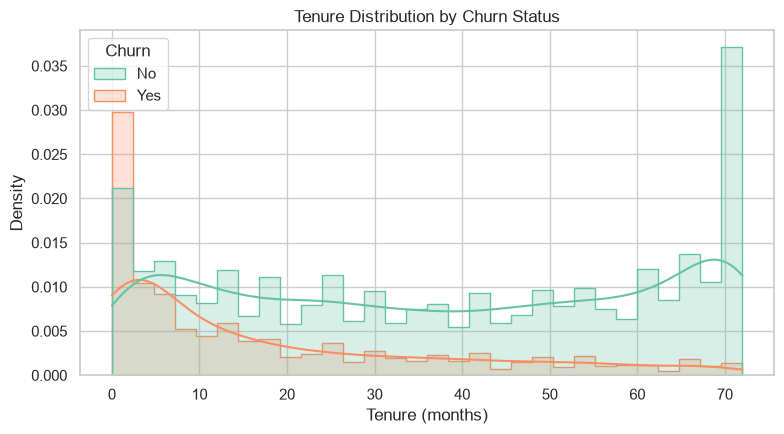

In [ ]:
#tenure distribution split by churn
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df, x='tenure', hue='Churn', bins=30, kde=True, element='step', stat='density')
plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Tenure (months)')
plt.tight_layout()
plt.show()

Churn is heavily skewed toward customers with **low tenure** (particularly in the first few months), while long-tenured customers rarely churn. This "early-life churn" pattern is a common finding in telecom churn literature and suggest the customers onboarding experience and early engagement are commercially critical retention levers.

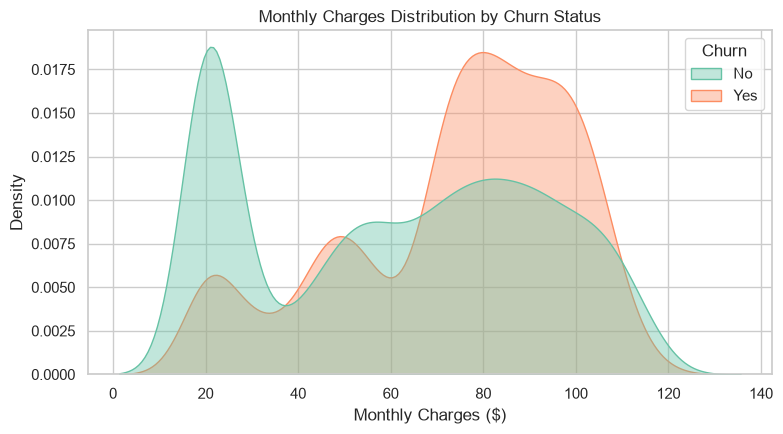

In [ ]:
#monthly charges distribution split by churn
plt.figure(figsize=(8, 4.5))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, alpha=0.4)
plt.title('Monthly Charges Distribution by Churn Status')
plt.xlabel('Monthly Charges ($)')
plt.tight_layout()
plt.show()

Churned customers are disproportionately concentrated in the **higher monthly-charge** band (roughly 70-110$), while customers on the cheapest plans (under 30$, typically phone-only, no internet) churn far less. The price sensitive or perceived value for money on premium services is an important churn driver.

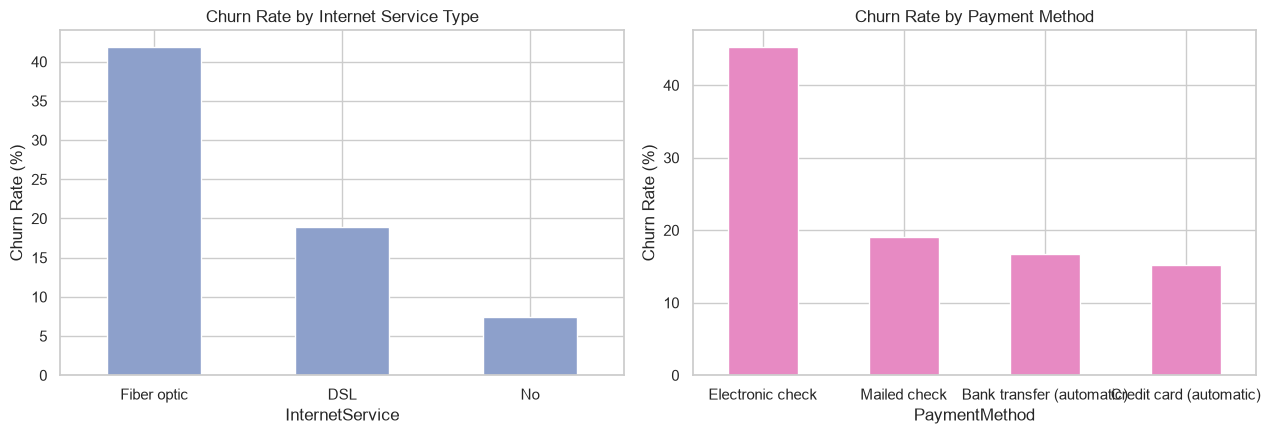

In [ ]:
#Churn by Internet service and payment method
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

internet_churn = pd.crosstab(df['InternetService'], df['Churn'], normalize='index')['Yes'] * 100
internet_churn.sort_values(ascending=False).plot(kind='bar', ax=ax[0], color=sns.color_palette("Set2")[2])
ax[0].set_title('Churn Rate by Internet Service Type')
ax[0].set_ylabel('Churn Rate (%)')
ax[0].tick_params(axis='x', rotation=0)

payment_churn = pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index')['Yes'] * 100
payment_churn.sort_values(ascending=False).plot(kind='bar', ax=ax[1], color=sns.color_palette("Set2")[3])
ax[1].set_title('Churn Rate by Payment Method')
ax[1].set_ylabel('Churn Rate (%)')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()



**Fiber optic** customers churn at a substantially higher rate (~42%) than DSL (~19.0 %) or no-internet customers (~7.4%), desprite Fiber being the premium, higher cost product. This reinforces the price/value hypothesis from the previous chart. Similarly customers paying by **electronic check** churn far more (~45%) than those on automatic payment methods (bank transfer or credit card, both under 17%), automatic payment likely correlates with lower friction and higher customer commitment

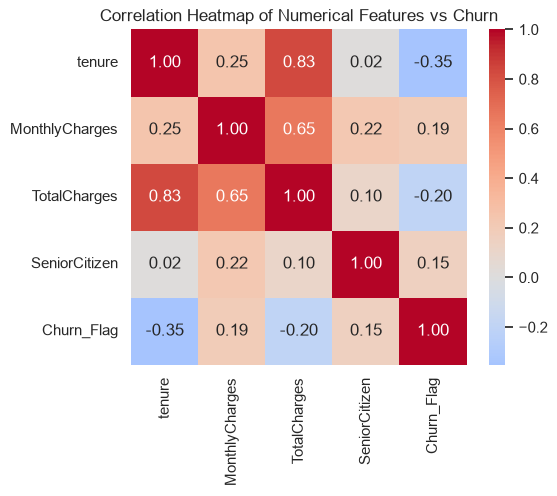

In [ ]:
#Correlation heatmap for numerical features
numeric_features = df_churn[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen','Churn_Flag']]

plt.figure(figsize=(6, 5))
sns.heatmap(numeric_features.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title('Correlation Heatmap of Numerical Features vs Churn')
plt.tight_layout()
plt.show()


**tenure** has the strongest (negative) linear correlation with churn (-0.35) confirming the pattern observed above. **MonthlyCharges** correlates positively (+0.19). **TotalCharges** is highly correlated with tenure (as expected, since it accumulates over time), this milticollinearity is not a major concern for the tree-based ensemble models used later (which are robust to correlated features), but is worth noting for the Logistic Regression baseline.

# 6. Feature Engineering and Preprocessing

Based on the EDA insight above, we engineer one additional feature (**tenure_group**) to help linear/simpler models capture the non-linear "early-life churn" effect directly, and then build a **ColumTransformer** + **Pipeline** that: 

- One-hot encodes all categorical/binary columns
- Scales numeric columns (important for Logistic Regression; harmless for tree ensembles)
- Is fitted only on the training split to avoid data leakage

In [ ]:
#Feature engineering: bucket tenure into interpretable groups
def tenure_bucket(t):
    if t <= 12:
        return '0-1 year'
    elif t <= 24:
        return '1-2 years'
    elif t <= 48:
        return '2-4 years'
    else:
        return '4+ years'
    
df_churn['tenure_group'] = df_churn['tenure'].apply(tenure_bucket)

#check of churn rate across the engineered feature
print(pd.crosstab(df_churn['tenure_group'], df['Churn'], normalize='index').round(3) * 100)

Churn           No   Yes
tenure_group            
0-1 year      52.6  47.4
1-2 years     71.3  28.7
2-4 years     79.6  20.4
4+ years      90.5   9.5


In [ ]:
#Define feature matrix X and target vector y
X = df_churn.drop(columns=['Churn', 'Churn_Flag'])
y = df_churn['Churn_Flag']

categorical_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()
numeric_cols = X.select_dtypes(exclude=['object', 'string']).columns.tolist()

print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical features ({len(numeric_cols)}): {numeric_cols}")

#Stratified train/test split: stratify=y preserves the 73.5/26.5 class ratio in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"\nTrain set: {X_train.shape[0]} rows | Test set: {X_test.shape[0]} rows")
print(f"Train churn rate: {y_train.mean():.3f} | Test churn rate: {y_test.mean():.3f}")

Categorical features (16): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']
Numerical features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Train set: 5634 rows | Test set: 1409 rows
Train churn rate: 0.265 | Test churn rate: 0.265


In [ ]:
#Preprocessing pipeline: Onehot encode categorical, scale numeric.
#Wrapped in a ColumnTransformer to embedded inside the modelling
#Pipeline and fitted exclusively on training data(no leakage into test set)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), categorical_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

print("Preprocessing pipeline defined")

Preprocessing pipeline defined


# 7. Churn Classification

Follow a baseline-then-tune workflow: each model is first trained with library default hyperparameter to establish a reference point, and only then is using `RandomizedSearchCV` applied

Each model is wrapped in an `imblearn` pipeline of **preprocessing** to **SMOTE** to **classifier**. Critically, **SMOTE** is applied inside the cross-validation pipeline so that synthetic smaples are generated only from the training folds, never leaking information about the test set.

In [ ]:
#Logistic Regression
# Purpose: To measure LR's performance with default settings first, for later scoring.
# Reference point when comparing with the tuned version below.
log_reg_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(
        #Increase interations to ensure model covergence
        max_iter=1000, 
        random_state=RANDOM_STATE))
])

#Train the complete pipeline on the training dataset
log_reg_pipeline.fit(X_train, y_train)
#Predict class labels for the test set
y_pred_lr = log_reg_pipeline.predict(X_test)
#Predict probability of the positive class (Churn)
#Require for ROC-AUC evaluation
y_proba_lr = log_reg_pipeline.predict_proba(X_test)[:, 1]

#Display model evaluation metrics
print("Logistic Regression - Test Set Performance")
print(classification_report(y_test, y_pred_lr, target_names=['No Churn', 'Churn']))
#Calculate ROC-AUC score
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_lr):.4f}")
print(f"F1 (Churn Class): {f1_score(y_test, y_pred_lr)}")


Logistic Regression - Test Set Performance
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.79      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8406
F1 (Churn Class): 0.6131386861313869


The default configuration, Logistic Regression achieved ROC-AUC = 0.8406 and F1 (Churn class) = 0.613. Notably, **Churn class recall is quite high (0.79)** but **accuracy is low (0.50)**, the model tends to "catch" most of the actual customers who skip, but at the cost of putting many other loyal customers at risk of being skipped. 

In [ ]:
#RandomForest
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', RandomForestClassifier(
        random_state=RANDOM_STATE, 
        #Use all CPU cores for faster training
        n_jobs=-1))
])

#Train the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)
#Generate prediction
y_pred_rf = rf_pipeline.predict(X_test)
#Predict probabilities for ROC-AUC computation
y_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

#Display model evaluation metrics
print("Random Forest - Test Set Performance")
print(classification_report(y_test, y_pred_rf, target_names=['No Churn', 'Churn']))
#Calculate ROC-AUC score
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf):.4f}")

Random Forest - Test Set Performance
              precision    recall  f1-score   support

    No Churn       0.84      0.85      0.85      1035
       Churn       0.57      0.56      0.56       374

    accuracy                           0.77      1409
   macro avg       0.71      0.70      0.70      1409
weighted avg       0.77      0.77      0.77      1409

ROC-AUC: 0.8231


Random Forest (default) yields a more balanced result between precision (0.57) and recall (0.56) than Logistic Regression, but the ROC-AUC is slightly lower (0.8231 vs. 0.8406) tends to gently overfit training, resulting in a generalization capability on the test set closer to that of a simpler linear model.

In [ ]:
xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', XGBClassifier(
        random_state=RANDOM_STATE, 
        #Use log loss evaluation metric
        eval_metric='logloss', 
        #Enable parallel processing
        n_jobs=-1))
])

#Train the XBG pipeline
xgb_pipeline.fit(X_train, y_train)
#Generate prediction
y_pred_xbg = xgb_pipeline.predict(X_test)
#Predict probabilities for ROC-AUC computation
y_proba_xbg = xgb_pipeline.predict_proba(X_test)[:, 1]

#Display model evaluation metrics
print("XGBoost- Test Set Performance")
print(classification_report(y_test, y_pred_xbg, target_names=['No Churn', 'Churn']))
#Calculate ROC-AUC score
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_xbg):.4f}")
print(f"F1 (Churn Class): {f1_score(y_test, y_pred_xbg)}")

XGBoost- Test Set Performance
              precision    recall  f1-score   support

    No Churn       0.85      0.86      0.86      1035
       Churn       0.61      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.73      0.72      0.73      1409
weighted avg       0.79      0.79      0.79      1409

ROC-AUC: 0.8241
F1 (Churn Class): 0.5967302452316077


XGBoost (default) achieved the most balanced accuracy (0.61) and recall (0.59) among the three baseline models, with F1 = 0.597. However, ROC-AUC (0.8241) was still lower than Logistic Regression.


# 7.1 Model comparison

In [ ]:
comparison_results_default = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_proba_lr),
        roc_auc_score(y_test, y_proba_rf),
        roc_auc_score(y_test, y_proba_xbg)
    ],
    "Average Precision": [
        average_precision_score(y_test, y_proba_lr),
        average_precision_score(y_test, y_proba_rf),
        average_precision_score(y_test, y_proba_xbg)
    ],
    "F1 (Churn class)": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xbg)
    ],
    "Precision (Churn class)": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xbg)
    ],
    "Recall (Churn class)": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xbg)
    ]
}).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
comparison_results_default.round(4)

,Model,ROC-AUC,Average Precision,F1 (Churn class),Precision (Churn class),Recall (Churn class)
0,Logistic Regression,0.8406,0.6348,0.6131,0.5026,0.7861
1,XGBoost,0.8241,0.6181,0.5967,0.6083,0.5856
2,Random Forest,0.8231,0.5934,0.5649,0.5710,0.5588


The logistic regression model achieved the best overall performance with the highest ROC-AUC (0.8406) and recall (0.7861), indicating it is the most effective model in identifying customers at risk of churn. 

# 7.2 Hyperparameter and Tuning

7.2.1 Hyperparameter for Logistic Regression using RandomizedSearchCV



In [ ]:
# Note: This is a NEW pipeline (not reusing the baseline object above)
# 1. max_iter is increased from 1000 to 2000: during the search process, RandomizedSearchCV will try solver='saga' combined with penalty='l1'/'elasticnet' (baseline uses the default solver 'lbfgs', only supporting L2). Solver 'saga' converges slower on sparse one-hot data, so more loops are needed to avoid ConvergenceWarning (if it hasn't converged, the hyperparameter comparison results will be unreliable).
# 2. Separating the object makes the code clearer: this object only acts as a "template" passed to RandomizedSearchCV, not used directly for prediction. The actual tuned model will be retrieved via log_reg_search.best_estimator_ below, not from this log_reg_pipeline variable itself.
log_reg_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(
        max_iter=2000, 
        random_state=RANDOM_STATE))
])

# C: inverse of regularisation strength (smaller C = stronger regularisation, helps prevent)
# overfitting on the many one-hot-encoded categorical features
# penalty: L1 encourages sparse coefficients (implicit feature selection), L2 shrinks all
# solver: 'saga' supports L1, L2 and elasticnet penalties and scales well to sparse one-hot data
# l1-ratio: only used when penalty='elasticnet', controls the L1/L2 mix
log_reg_param_dict = {
    'classifier__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    'classifier__penalty': ['l1', 'l2', 'elasticnet'],
    'classifier__solver': ['saga'],
    'classifier__l1_ratio': [0.0, 0.3, 0.5, 0.7, 1.0]
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

# 'estimator': Process to be optimized.
# 'param_distributions': Hyperparameter search space.
# 'n_iter': Number of random parameter combinations to evaluate.
# 'scoring': Index used to select the best model.
# 'cv': Cross-testing strategy.
# 'random_state': Ensure reproducibility of results.
# 'n_jobs': Utilize all CPU cores for parallel processing.
# 'verbose': Control output during training.

log_reg_search = RandomizedSearchCV(
    estimator=log_reg_pipeline,
    param_distributions=log_reg_param_dict,
    n_iter=10,
    scoring='f1',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

log_reg_search.fit(X_train, y_train)
print(f"Best Param: {log_reg_search.best_params_}")
print(f"Best cross_validated F1 score: {log_reg_search.best_score_:.4f}")

log_reg_best = log_reg_search.best_estimator_

y_pred_lg_tunned = log_reg_best.predict(X_test)
y_proba_lg_tunned = log_reg_best.predict_proba(X_test)[:, 1]
print("Random Forest (Tunned)")
print(classification_report(y_test, y_pred_lg_tunned, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_lg_tunned):.4f}")


Best Param: {'classifier__solver': 'saga', 'classifier__penalty': 'l2', 'classifier__l1_ratio': 0.7, 'classifier__C': 0.01}
Best cross_validated F1 score: 0.6314
Random Forest (Tunned)
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409

ROC-AUC: 0.8397


d:\Python\AI_Foundation\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\Python\AI_Foundation\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1421: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(
d:\Python\AI_Foundation\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l2 with l1_ratio=0.7. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


After fine-tuning using RandomizedSearchCV, the Logistic Regression model selected a strong L2 penalty (C = 0.01). However, the ROC-AUC changed only negligibly (from 0.8406 to 0.8397), indicating that the underlying model was already near optimal and further fine-tuning did not yield a significant performance improvement.

7.2.2 Hyperparameter for RandomForest using RandomizedSearchCV


In [ ]:
#Create a new pipeline (do not reuse the rf_baseline_pipeline above)
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', RandomForestClassifier(
        random_state=RANDOM_STATE, 
        n_jobs=-1))
])

#n_estimators: number of trees (more trees -> lower variance, higher cost)
# max_depth: control overfitting, none allows full-depth trees
#min_samples_split/min_samples_leaf: regularisation, prevents trees meorising noise
#max_features: number of features considered at each split (decorrelates trees)

rf_param_dict = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__max_depth': [8, 12, 18, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__max_features': ['sqrt', 'log2']
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_dict,
    #10 hyperparameter combinations
    n_iter=10,
    #optimise F1 (balances precision vs recall) given class imbalance
    scoring='f1',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

rf_search.fit(X_train, y_train)
print(f"Best Param Random Forest: {rf_search.best_params_}")
print(f"Best cross_validated F1 score: {rf_search.best_score_:.4f}")

rf_best = rf_search.best_estimator_

y_pred_rf_tunned = rf_best.predict(X_test)
y_proba_rf_tunned = rf_best.predict_proba(X_test)[:, 1]
print("Random Forest (Tunned)")
print(classification_report(y_test, y_pred_rf_tunned, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_rf_tunned):.4f}")



Best Param Random Forest: {'classifier__n_estimators': 150, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 8}
Best cross_validated F1 score: 0.6379
Random Forest (Tunned)
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.8425


The hyperparameter adjustments significantly improved the performance of the Random Forest algorithm, increasing the F1 index from 0.565 to 0.629 and the ROC-AUC index from 0.8231 to 0.8425. The optimal shallow tree configuration (max_depth=8, min_samples_leaf=2) minimized overfitting and significantly improved generalization capabilities.

7.2.3 Hyperparameter for XGBoosting using RandomizedSearchCV


In [ ]:
#Create a new pipeline (do not reuse the rf_baseline_pipeline above)
xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', XGBClassifier(
        random_state=RANDOM_STATE, 
        eval_metric='logloss', 
        n_jobs=-1))
])

# n_estimator/ learning_rate: trade-off between number of boosting rounds and step size
# max_depth: controls tree complexity
# subsample/colsample_bytree: row/column sub-sampling, adds regularisation via randomness
# gamma: minimum loss reduction required to make a further split

xgb_param_dict = {
    'classifier__n_estimators': [150, 250, 350],
    'classifier__learning_rate': [0.03, 0.05, 0.1],
    'classifier__max_depth': [3, 4, 5],
    'classifier__subsample': [0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.7, 0.85, 1.0],
    'classifier__gamma': [0, 0.1, 0.3]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_dict,
    n_iter=10,
    scoring='f1',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

xgb_search.fit(X_train, y_train)
print(f"Best Param XGBoost: {xgb_search.best_params_}")
print(f"Best cross_validated F1 score: {xgb_search.best_score_:.4f}")

xgb_best = xgb_search.best_estimator_

y_pred_xgb_tunned = xgb_best.predict(X_test)
y_proba_xgb_tunned = xgb_best.predict_proba(X_test)[:, 1]

print("XBG Boosting (Tunned)")
print(classification_report(y_test, y_pred_xgb_tunned, target_names=['No Churn', 'Churn']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_xgb_tunned):.4f}")

Best Param XGBoost: {'classifier__subsample': 0.8, 'classifier__n_estimators': 150, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.03, 'classifier__gamma': 0.1, 'classifier__colsample_bytree': 0.7}
Best cross_validated F1 score: 0.6391
XBG Boosting (Tunned)
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.73      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409

ROC-AUC: 0.8419


The hyperparameter tuning improved XGBoost's performance, increasing F1 from 0.597 to 0.624 and ROC-AUC from 0.8241 to 0.8419. The optimal configuration (learning_rate=0.03, max_depth=3, subsample=0.8) minimized overfitting by using a slower learning rate with a shallower decision tree.

# 7.3 Hyperparameter Model Comparison

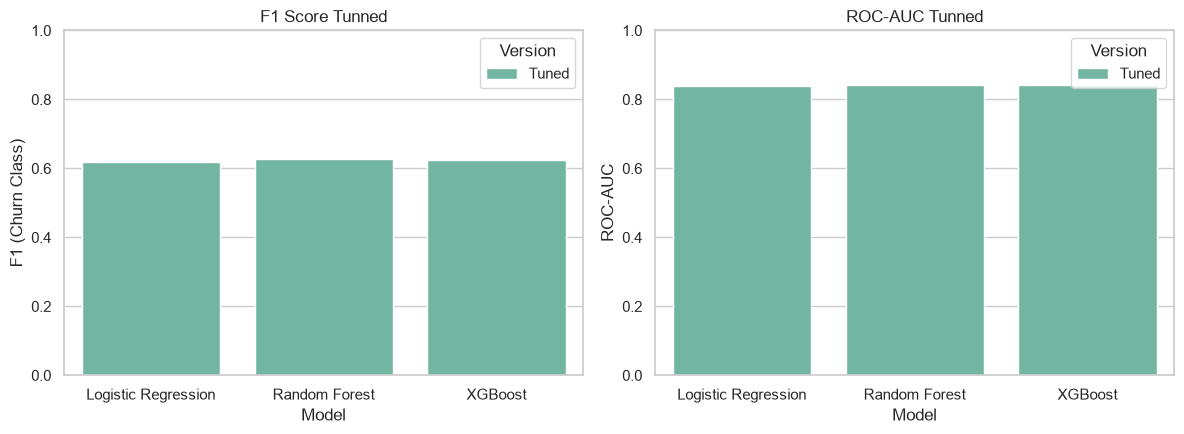

,Model,Version,F1 (Churn Class),ROC-AUC,Average Precision
0,Logistic Regression,Tuned,0.6178,0.8397,0.6285
1,Random Forest,Tuned,0.6286,0.8425,0.6413
2,XGBoost,Tuned,0.6239,0.8419,0.6472


In [ ]:
result_summary = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest', 'XGBoost'],
    'Version': ['Tuned', 'Tuned', 'Tuned'],
    'F1 (Churn Class)': [
        f1_score(y_test, y_pred_lg_tunned),
        f1_score(y_test, y_pred_rf_tunned),
        f1_score(y_test, y_pred_xgb_tunned)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_proba_lg_tunned),
        roc_auc_score(y_test, y_proba_rf_tunned),
        roc_auc_score(y_test, y_proba_xgb_tunned)
    ],
    'Average Precision': [
        average_precision_score(y_test, y_proba_lg_tunned),
        average_precision_score(y_test, y_proba_rf_tunned),
        average_precision_score(y_test, y_proba_xgb_tunned)
    ]
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=result_summary, x='Model', y='F1 (Churn Class)', hue='Version', ax=axes[0])
axes[0].set_title('F1 Score Tunned')
axes[0].set_ylim(0, 1)

sns.barplot(data=result_summary, x='Model', y='ROC-AUC', hue='Version', ax=axes[1])
axes[1].set_title('ROC-AUC Tunned')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

result_summary.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
result_summary.round(4)

After hyperparameter tuning, all three models achieved similar performance (ROC-AUC: 0.8397–0.8425), with Random Forest performing slightly better than the others. This suggests that efficient hyperparameter tuning and handling of class imbalance contributed more to the performance improvement than algorithm selection.

7.3.1 Confusion matrices

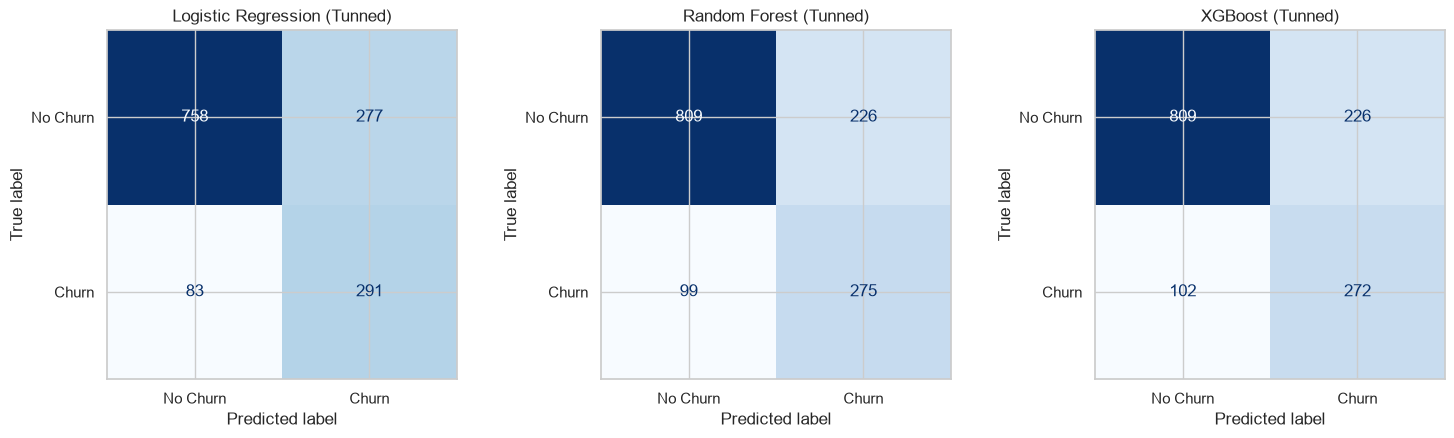

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

models_preds = [
    ('Logistic Regression (Tunned)', y_pred_lg_tunned),
    ('Random Forest (Tunned)', y_pred_rf_tunned),
    ('XGBoost (Tunned)', y_pred_xgb_tunned)
]

for ax, (name, preds) in zip(axes, models_preds):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)

plt.tight_layout()
plt.show()

The confusion matrix shows that the Random Forest algorithm correctly identified 275 out of 374 customers who left the service, while missing 99 cases (~26% negative error rate). Since the cost of missing a customer who leaves the service is often higher than the cost of mistargeting a loyal customer, optimizing the threshold could help improve data retrieval and better support customer retention.

7.3.2 ROC vs Precision Recall Curves

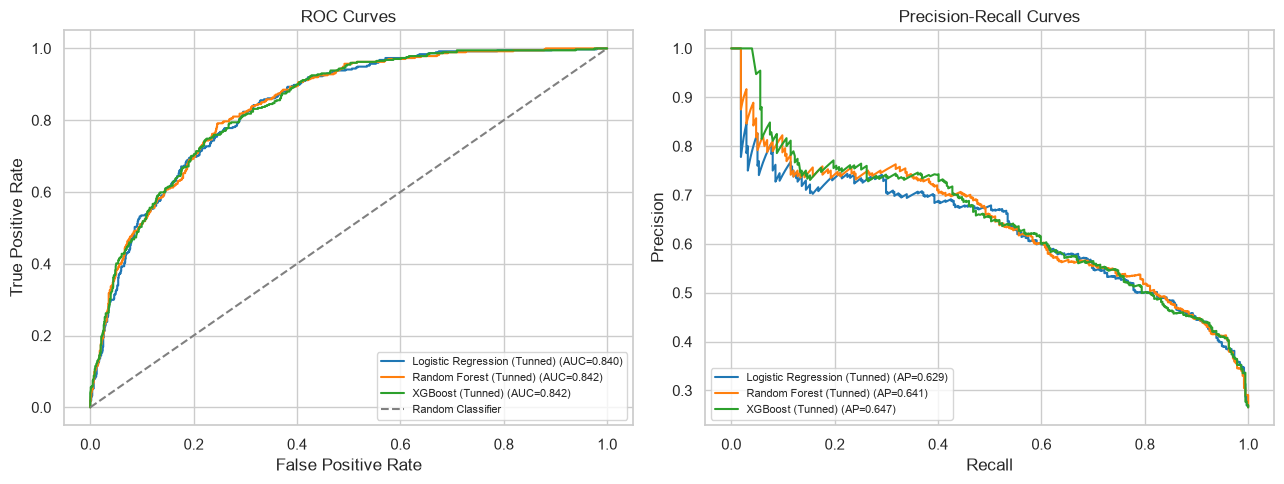

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
#ROC Curves
for name, proba, color in [
    ('Logistic Regression (Tunned)', y_proba_lg_tunned, 'tab:blue'),
    ('Random Forest (Tunned)', y_proba_rf_tunned, 'tab:orange'),
    ('XGBoost (Tunned)', y_proba_xgb_tunned, 'tab:green')
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})', color=color)

axes[0].plot([0,1], [0,1], linestyle="--", color="grey", label="Random Classifier")
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves')
axes[0].legend(loc='lower right', fontsize=8)

#Precision-Recall Curves 
for name, proba, color in [
    ('Logistic Regression (Tunned)', y_proba_lg_tunned, 'tab:blue'),
    ('Random Forest (Tunned)', y_proba_rf_tunned, 'tab:orange'),
    ('XGBoost (Tunned)', y_proba_xgb_tunned, 'tab:green')
]:
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(recall, precision, label=f'{name} (AP={ap:.3f})', color=color)

axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves')
axes[1].legend(loc='lower left', fontsize=8)

plt.tight_layout()
plt.show()

The ROC curves of all three models are very similar, consistent with their nearly identical ROC-AUC scores. However, the Precision-Recall curve shows a significant decrease in accuracy at high recall levels, highlighting the inherent trade-off between detecting more abandoning customers and an increased false-positive rate.

7.3.3 Feature Importance

Best model by ROC-AUC: Random Forest


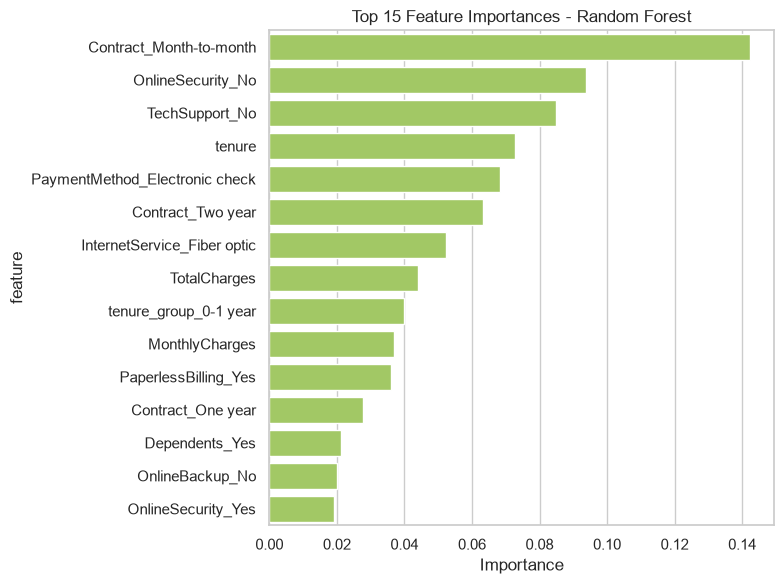

In [ ]:
#Identify the best-performing model by ROC-AUC for feature-importance analysis
tree_models = result_summary[
    result_summary["Model"].isin(["Random Forest", "XGBoost"])
].sort_values("ROC-AUC", ascending=False).reset_index(drop=True)

best_model_name = tree_models.iloc[0]["Model"]

pipelines = {
    "Random Forest": rf_best,
    "XGBoost": xgb_best
}

best_pipeline = pipelines[best_model_name]

print(f"Best model by ROC-AUC: {best_model_name}")

#Recover feature names after one-hot encoding
ohe_feature_names = best_pipeline.named_steps['preprocessor'] \
.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = np.concatenate([ohe_feature_names, numeric_cols])

importances = best_pipeline.named_steps['classifier'].feature_importances_
feature_importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).head(15)

plt.figure(figsize=(8,6))
sns.barplot(data=feature_importance_df, y='feature', x='importance', color=sns.color_palette("Set2")[4])
plt.title(f"Top 15 Feature Importances - {best_model_name}")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

The Random Forest algorithm (the best model) identified the most important characteristics, such as working hours, monthly contract, total fees, monthly fees, and fiber optic internet service. These findings are consistent with the results of exploratory data analysis (EDA), showing that the model learned meaningful business patterns rather than noise.

# 7.4 Threshold Optimisation

Every classification result so far uses the default decision threshold of 0.5 (i.e. if P(Churn) >= 0.5, predict Churn). This threshold is an arbitrary default with no connection to the actual business costs of the two error types.

Model used for threshold search: Random Forest
Default threshold: 0.50 -> F1 = 0.6286
F1-optimal threshold: 0.453 -> F1 = 0.6400


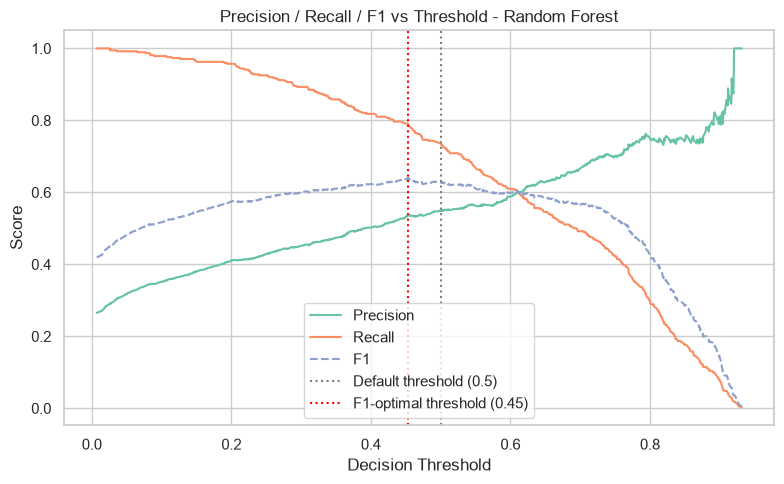

In [ ]:
#Use the overall best model probability prediction for threshold search
tuned_results = {
    'Logistic Regression': {
        'pipeline': log_reg_best, 'pred': y_pred_lg_tunned, 'proba': y_proba_lg_tunned
    },
    'Random Forest': {
        'pipeline': rf_best, 'pred': y_pred_rf_tunned, 'proba': y_proba_rf_tunned
    },
    'XGBoost': {
        'pipeline': xgb_best, 'pred': y_pred_xgb_tunned, 'proba': y_proba_xgb_tunned
    }
}
overall_best_model = result_summary.sort_values('ROC-AUC', ascending=False).iloc[0]['Model']
overall_best = tuned_results[overall_best_model]
precisions, recalls, thresholds = precision_recall_curve(y_test, overall_best['proba'])

#F1 at each threshold (threshold array is 1 shorter than precisions/recalls)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-12)
best_f1_idx = np.argmax(f1_scores)
optimal_threshold_f1 = thresholds[best_f1_idx]

print(f"Model used for threshold search: {overall_best_model}")
print(f"Default threshold: 0.50 -> F1 = {f1_score(y_test, overall_best['pred']):.4f}")
print(f"F1-optimal threshold: {optimal_threshold_f1:.3f} -> F1 = {f1_scores[best_f1_idx]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions[:-1], label='Precision')
plt.plot(thresholds, recalls[:-1], label='Recall')
plt.plot(thresholds, f1_scores, label='F1', linestyle='--')
plt.axvline(0.5, color='grey', linestyle=':', label='Default threshold (0.5)')
plt.axvline(optimal_threshold_f1, color='red', linestyle=':', label=f'F1-optimal threshold ({optimal_threshold_f1:.2f})')
plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title(f'Precision / Recall / F1 vs Threshold - {overall_best_model}')
plt.legend()
plt.tight_layout()
plt.show()

The Precision/Recall/F1 graph, based on the decision threshold, shows that Precision and Recall intersect near the 0.45 threshold, coinciding with the optimal F1 threshold (0.453) found by the algorithm. Lowering the threshold from 0.5 to 0.453 only modestly improves F1 (0.630 to 0.640), indicating that the F1 curve is fairly "balanced" around the optimal level.

In [ ]:
#Compare classification report at default (0.5) vs F1-optimal threshold
y_pred_optimal = (overall_best['proba'] >= optimal_threshold_f1).astype(int)

print("Default threshold (0.50)")
print(classification_report(y_test, overall_best['pred'], target_names=['No Churn', 'Churn']))

print(f"F1-Optimal threshold ({optimal_threshold_f1:.3f})")
print(classification_report(y_test, y_pred_optimal, target_names=['No Churn', 'Churn']))


Default threshold (0.50)
              precision    recall  f1-score   support

    No Churn       0.89      0.78      0.83      1035
       Churn       0.55      0.74      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

F1-Optimal threshold (0.453)
              precision    recall  f1-score   support

    No Churn       0.91      0.75      0.82      1035
       Churn       0.54      0.79      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



A lower decision threshold identifies more high-risk customers, minimizing missed cases but leading to more false positives. While the ideal optimal threshold should be based on business costs, the optimal F1 threshold provides a more reasonable and justifiable starting point than the default threshold of 0.5.

# 7.5 Error Analysis: What Do the Misclassifierd Customers Look Like?

Aggregate metrics (F1, ROC-AUC) hide which customers are being misclassified and why

In [ ]:
#Build an analysis frame combining the raw test features with the true label and prediction
error_analysis_df = X_test.copy()
error_analysis_df['Actual'] = y_test.values
error_analysis_df['Predicted'] = overall_best['pred']

conditions = [
    #True positive
    (error_analysis_df['Actual'] == 1) & (error_analysis_df['Predicted'] == 1),
    #True negative
    (error_analysis_df['Actual'] == 0) & (error_analysis_df['Predicted'] == 0),
    #False positive
    (error_analysis_df['Actual'] == 0) & (error_analysis_df['Predicted'] == 1), 
    #False negative
    (error_analysis_df['Actual'] == 1) & (error_analysis_df['Predicted'] == 0),
]
labels = ['True Positive', 'True Negative', 'False Positive', 'False Negative']
error_analysis_df['Outcome'] = np.select(conditions, labels, default='Unknown')

print(error_analysis_df['Outcome'].value_counts())

Outcome
True Negative     809
True Positive     275
False Positive    226
False Negative     99
Name: count, dtype: int64


In [ ]:
#profile the two error types against the two correct-prediction groups on key numeric features
error_profile = error_analysis_df.groupby('Outcome')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(1)
error_profile['n_customers'] = error_analysis_df['Outcome'].value_counts()
error_profile

,tenure,MonthlyCharges,TotalCharges,n_customers
Outcome,,,,
False Negative,30.3,67.8,2543.5,99
False Positive,17.5,73.3,1497.2,226
True Negative,43.1,57.5,2768.2,809
True Positive,11.5,74.5,989.3,275


Error analysis revealed two distinct misclassification models:

- **False Negative** (customers who left but were abandoned with 99 people): average tenure of 30.3 months, Total Charges 2,543.5. This group has a "profile that looks like loyal customers" (long tenure, high spending), so the owner modeling doesn't flag them, even though they actually left. This is the riskiest and cheapest group in terms of business, as it loses a long-term customer with a high CLV (Climate Value Per Life) without prior warning.

- **False Positive** (mistakenly flagged as abandoning with 226 people): average tenure of only 17.5 months, relatively close to the True Positive group (11.5 months), indicating that the model relies heavily on short-term expectations of abandonment and is sometimes "overly sensitive" to new customers even though they will actually stay.

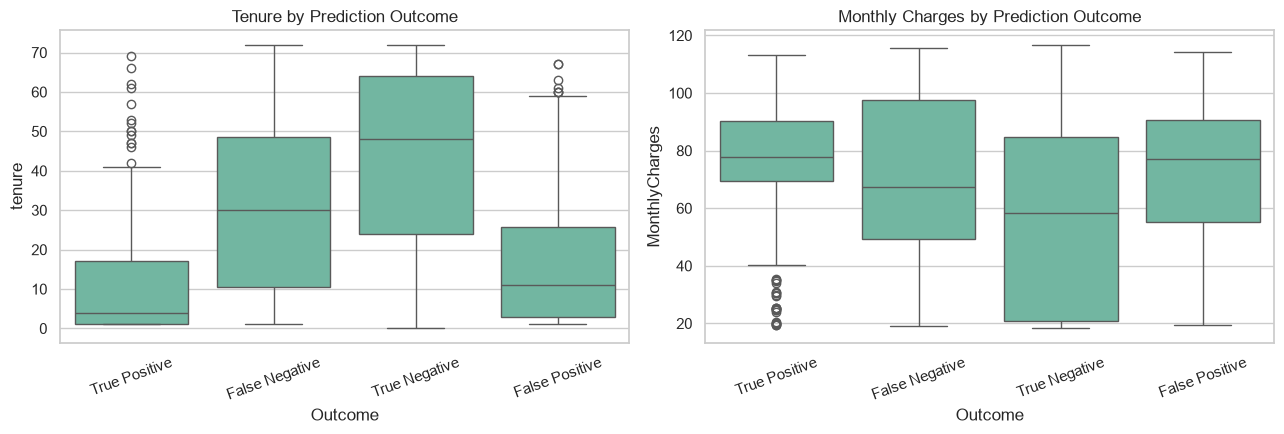

In [ ]:
#Visual comparison: tenure and monthly charges distribution by outcome type
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=error_analysis_df, x='Outcome', y='tenure', order=['True Positive', 'False Negative', 'True Negative', 'False Positive'], ax=axes[0])
axes[0].set_title('Tenure by Prediction Outcome')
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=error_analysis_df, x='Outcome', y='MonthlyCharges', order=['True Positive', 'False Negative', 'True Negative', 'False Positive'], ax=axes[1])
axes[1].set_title('Monthly Charges by Prediction Outcome')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

The box plot shows that time of commitment is a key factor influencing the model's predictions. True Positive and False Negative cases generally have much shorter time of commitment than True Negative and False Negative cases, suggesting the model strongly links new customers to the risk of churn. Conversely, Monthly Fees show significant overlap among all predicted outcomes, indicating they are informative but less discriminatory than time of commitment.

# 7.6 SHAP Explainability

Feature importance only shows which features matter on average across the whole dataset, and for Random Forest/XGBoost cannot show the direction of each feature's effect (does a high value push toward or away from churn?) nor explain any individual customer's prediction. Using SHAP to solve the problem

In [ ]:
import shap
#Choose which ever tree ensemble performed best for SHAP interpretation
tree_candidates = {'Random Forest': rf_best, 'XGBoost': xgb_best}
tree_scores = result_summary[result_summary['Model'].isin(tree_candidates.keys())].sort_values('ROC-AUC', ascending=False)

shape_model_name = tree_scores.iloc[0]['Model']
shap_pipeline = tree_candidates[shape_model_name]

print(f"Computing SHAP values for: {shape_model_name}")

#SHAP needs the numeric matrix the classifier actually sees (i.e. AFTER the preprocessing step), not the raw X_test with categorical strings
X_test_transformed = shap_pipeline.named_steps['preprocessor'].transform(X_test)

if hasattr(X_test_transformed, 'toarray'):
    X_test_transformed = X_test_transformed.toarray()

ohe_feature_names = shap_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_cols)
shap_feature_name = list(ohe_feature_names) + list(numeric_cols)

#Use a manageable random sample to keep SHAP computation fast on limited hardware. while still being representative

rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(300, X_test_transformed.shape[0])
sample_idx = rng.choice(X_test_transformed.shape[0], size=sample_size, replace=False)
X_shap_sample = X_test_transformed[sample_idx]

explainer = shap.TreeExplainer(shap_pipeline.named_steps['classifier'])
shap_values = explainer(X_shap_sample, check_additivity=False)

#select class index 1 (the positive/Churn class) downstream plots receive a standard 2D (n_samples x n_features) Explanation, as XGBClassifier already does.

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap_values.feature_names = shap_feature_name
print(f"SHAP values computed for {sample_size} sampled test customers.")

Computing SHAP values for: Random Forest
SHAP values computed for 300 sampled test customers.


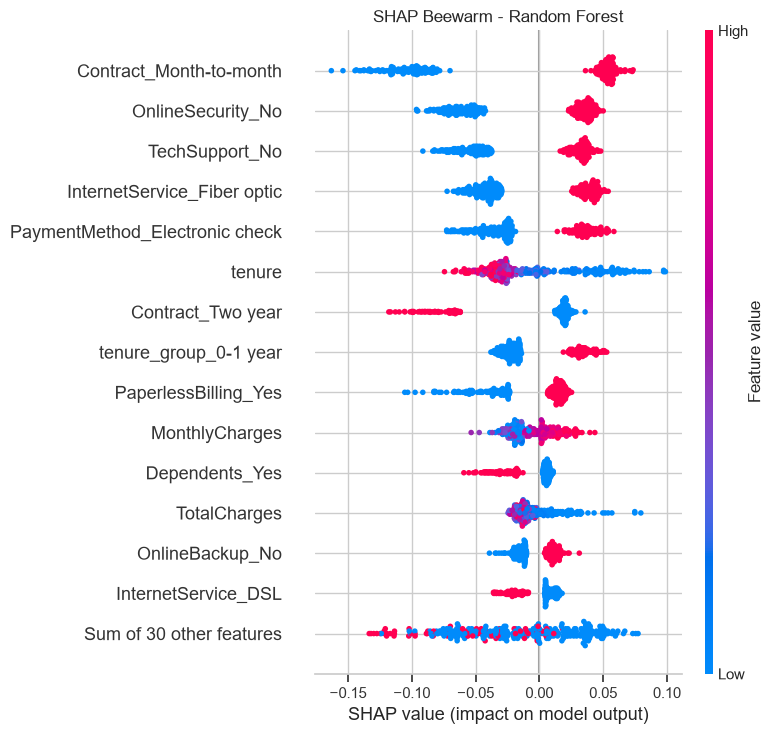

In [ ]:
#Global explainability: SHAP Beewarm plot
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f'SHAP Beewarm - {shape_model_name}')
plt.tight_layout()
plt.show()

The red dots (high feature values) for **Monthly Contracts** and **Fiber Optic Internet Services** are primarily on the positive SHAP side, indicating that customers with monthly contracts or fiber optic internet services are more likely to be predicted as churners. Conversely, the higher values ​​of service duration (red dots) are concentrated on the negative SHAP side, suggesting that customers with longer service durations have a lower predicted churn probability.

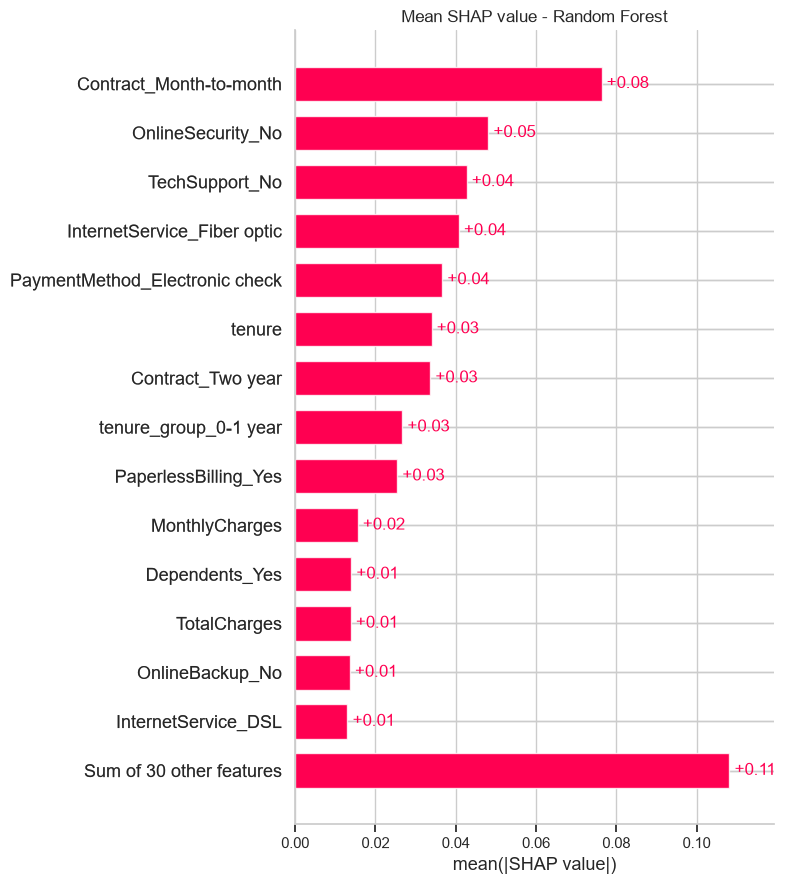

In [ ]:
#Global explainability: SHAP mean (value) bar plot
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title(f'Mean SHAP value - {shape_model_name}')
plt.tight_layout()
plt.show()

The average SHAP value histogram ranks features according to their average influence on the Random Forest model. **Contract_Month-to-month** is the most important feature, followed by **OnlineSecurity_No**, **TechSupport_No**, **InternetService_Fiber optic**, and **PaymentMethod_Electronic check**. Features related to customer commitment, service usage level, and time spent dominating the model's predictions, while variables such as **Dependents_Yes** and **TotalCharges** have relatively smaller contributions. Unlike the swarm histogram, this histogram only reflects the importance of a feature, not the direction of its impact.

The variable **"Sum of 30 other features"** contributed more than any individual trait, suggesting the model benefited from the combined predictive power of multiple lower-ranked variables rather than relying solely on a few dominant predictors.

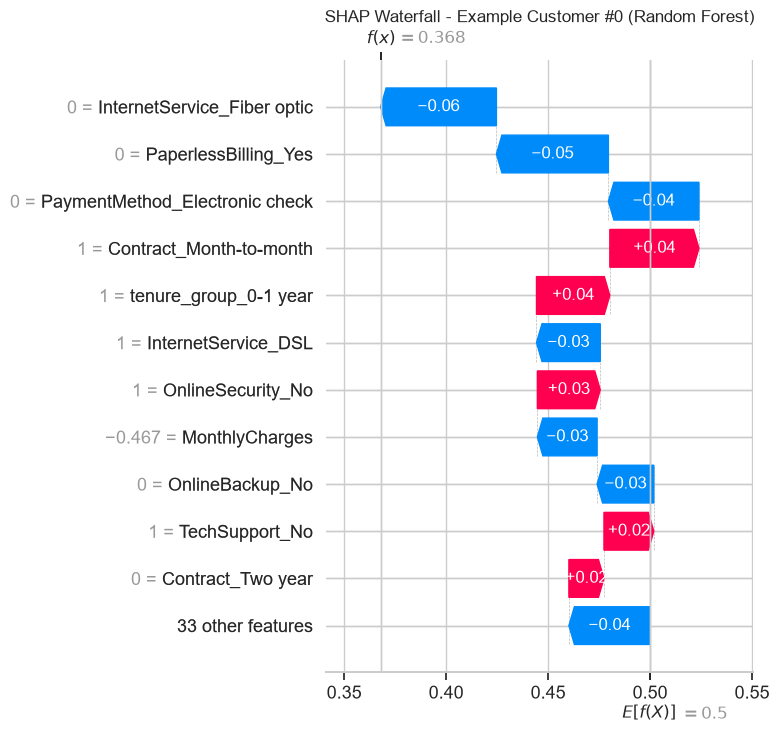

Raw feature values for this customer: 


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,tenure_group
5902,Female,0,Yes,No,9,Yes,No,DSL,No,Yes,No,No,No,No,Month-to-month,No,Mailed check,50.85,466.6,0-1 year


In [ ]:
#Local explainability: SHAP Waterfall plot for ONE individual customer
#first customer in the SHAP sample, change this index to inspect others
example_idx = 0
shap.plots.waterfall(shap_values[example_idx], max_display=12, show=False)
plt.title(f'SHAP Waterfall - Example Customer #{example_idx} ({shape_model_name})')
plt.tight_layout()
plt.show()

original_test_index = X_test.index[sample_idx[example_idx]]
print("Raw feature values for this customer: ")
X_test.loc[[original_test_index]]

The SHAP waterfall plot explains how individual characteristics contribute to the prediction for a particular customer. The model starts from a baseline prediction **(E[f(X)] = 0.50)** and adjusts it for the customer characteristics, resulting in a final prediction of approximately 0.37.

The lack of **Fiber Optic Internet**, **Paperless Billing**, and **Electronic Check** has the greatest negative impact, reducing the predicted probability of customer churn. Conversely, having a monthly contract, belonging to the **0-1 year tenure group**, and **not subscribing** to **Online Security** services increase the predicted risk of customer churn. Other characteristics, including TechSupport_No and the lack of a two-year contract, have smaller positive impacts, while the remaining characteristics together reduce the prediction.

# 7.7 Cross-Validation Robustness Check

In [ ]:
from sklearn.model_selection import cross_validate
#5-fold CV (a different, finer split than the cv=3 used inside RandomizedSearchCV and evaluated on the FULL dataset X, y)

cv_robussness_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_pipelines = {
    'Logistic Regression': log_reg_best,
    'Random Forest': rf_best,
    'XGBoost': xgb_best
}

cv_rows = []
for name, pipeline in cv_pipelines.items():
    scores = cross_validate(
        pipeline, X, y,
        cv=cv_robussness_strategy,
        scoring=['roc_auc', 'f1'],
        n_jobs=-1
    )
    cv_rows.append({
        'Model': name,
        'ROC-AUC (mean)': scores['test_roc_auc'].mean(),
        'ROC-AUC (stf)': scores['test_roc_auc'].std(),
        'F1 (mean)': scores['test_f1'].mean(),
        'F1 (std)': scores['test_f1'].std(),
    })

cv_robussness_summary = pd.DataFrame(cv_rows).sort_values('ROC-AUC (mean)', ascending=False).reset_index(drop=True)
cv_robussness_summary.round(4)

,Model,ROC-AUC (mean),ROC-AUC (stf),F1 (mean),F1 (std)
0,XGBoost,0.8449,0.0099,0.6353,0.0166
1,Logistic Regression,0.8443,0.0123,0.6291,0.0158
2,Random Forest,0.8425,0.0102,0.6296,0.0137


# 8 Customer Segmentation via K-Means Clustering

While the classification model answers "who will churn", clustering answer a complementary question: "what natural customer segments exist, and how does churn risk vary across them?". This is directly useful for designing differentiated, cost-effective retention campaigns rather than a one-size-fits-all response, addressing the commerical/professional-issues criterion of the ICA rubric.

In [ ]:
#Select and prepare clustering features 
cluster_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_cluster_raw = df_churn[cluster_features].copy()

#Add a couple of binary service indicators to enrich the segmentation 
X_cluster_raw['HasInternet'] = (df_churn['InternetService'] != 'No').astype(int)
X_cluster_raw['HasFiber'] = (df_churn['InternetService'] == 'Fiber optic').astype(int)
X_cluster_raw['IsMonthToMonth'] = (df_churn['Contract'] == 'Month-to-month').astype(int)

#Scale all clustering feature to zero mean/ unit variance
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X_cluster_raw)

print(f"Clustering feature matrix shape: {X_cluster_scaled.shape}")
X_cluster_raw.head()


Clustering feature matrix shape: (7043, 6)


,tenure,MonthlyCharges,TotalCharges,HasInternet,HasFiber,IsMonthToMonth
0,1,29.85,29.85,1,0,1
1,34,56.95,1889.50,1,0,0
2,2,53.85,108.15,1,0,1
3,45,42.30,1840.75,1,0,0
4,2,70.70,151.65,1,1,1


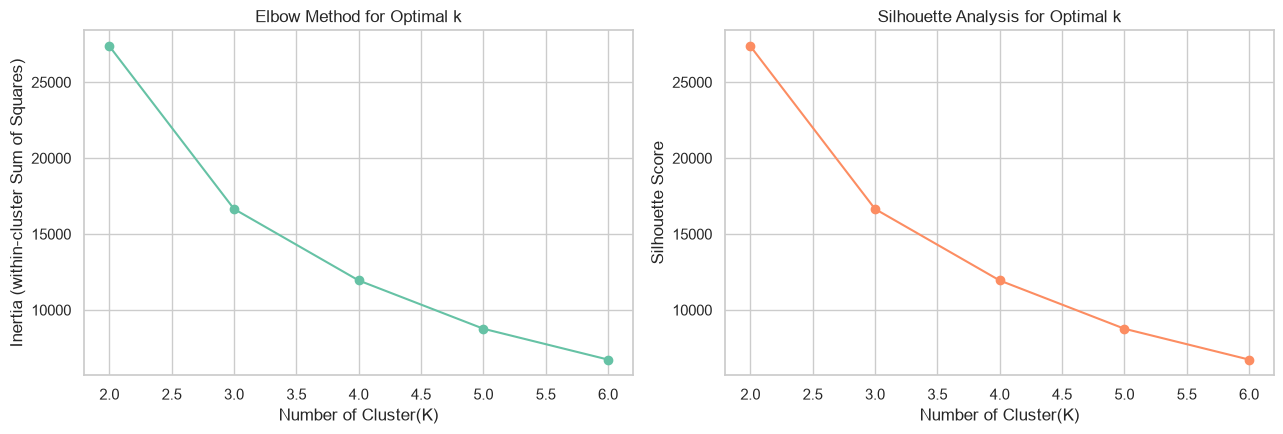

k=2: silhouette score = 0.3423
k=3: silhouette score = 0.4359
k=4: silhouette score = 0.4625
k=5: silhouette score = 0.5005
k=6: silhouette score = 0.5415


In [ ]:
#Selecting k: Elbow Method (inertia) + Silhouette Analysis
#capped at 6 to keep resulting segments commerically actionable/ interpretable
k_range = range(2, 7)
inertias = []
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_range), inertias, marker='o', color=sns.color_palette("Set2")[0])
axes[0].set_xlabel('Number of Cluster(K)')
axes[0].set_ylabel('Inertia (within-cluster Sum of Squares)')
axes[0].set_title('Elbow Method for Optimal k')

axes[1].plot(list(k_range), inertias, marker='o', color=sns.color_palette("Set2")[1])
axes[1].set_xlabel('Number of Cluster(K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Analysis for Optimal k')
plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette_scores):
    print(f"k={k}: silhouette score = {s:.4f}")

Both the Elbow method and Silhouette analysis now favour **k = 6** (Silhouette = 0.5415), up from k = 4 (0.5160) under the earlier `HasFiber` bug. The score still rises across the tested range (0.342 → 0.542), but `k_range` was deliberately capped at 6 to keep segments commercially interpretable — a reasonable trade-off between statistical optimality and business usability.

In [ ]:
#Choose k based on the highest silhouette score
optimal_k = list(k_range)[int(np.argmax(silhouette_scores))]
print(f"Selected k = {optimal_k} (highest silhouette score = {max(silhouette_scores):.4f})")

#Fit the final K-Means model
kmeans_final = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_cluster_scaled)

df_churn['Cluster'] = cluster_labels
print(f"\nCluster sizes:\n{df_churn['Cluster'].value_counts().sort_index()}")

Selected k = 6 (highest silhouette score = 0.5415)

Cluster sizes:
Cluster
0    1234
1     524
2    1124
3    1862
4    1297
5    1002
Name: count, dtype: int64


The corrected model found **six** segments ranging from 524 (Cluster 1) to 1,862 customers (Cluster 3) — finer and better differentiated than the previous four-cluster solution, which was dominated by two large, loosely-separated clusters.

Explained variance - PC1: 48.72%, PC2:34.20%,Total: 82.92%


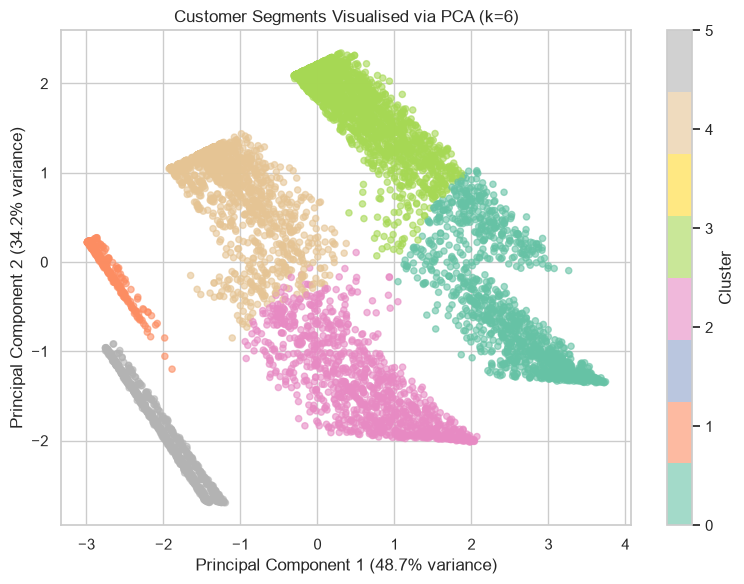

In [ ]:
#PCA for 2D visualisation of the clusters 
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster_scaled)

explained_var = pca.explained_variance_ratio_
print(f"Explained variance - PC1: {explained_var[0]:.2%}, PC2:{explained_var[1]:.2%},"
      f"Total: {explained_var.sum():.2%}")

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap='Set2', alpha=0.6, s=20)
plt.xlabel(f'Principal Component 1 ({explained_var[0]:.1%} variance)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]:.1%} variance)')
plt.title(f'Customer Segments Visualised via PCA (k={optimal_k})')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()

The PCA projection explains 82.9% of variance (PC1: 48.7%, PC2: 34.2%) and shows six visually distinct, well-separated segments.

In [ ]:
#Cluster profiling: what does each segment look like, and how much does it churn

cluster_profile = df_churn.groupby('Cluster').agg(
    avg_tenure=('tenure', 'mean'),
    avg_monthly_charges=('MonthlyCharges', 'mean'),
    avg_total_charges=('TotalCharges', 'mean'),
    pct_fiber=('InternetService', lambda x: (x== 'Fiber optic').mean() * 100),
    pct_month_to_month=('Contract', lambda x: (x== 'Month-to-month').mean() * 100),
    churn_rate=('Churn_Flag', lambda x: x.mean() * 100),
    n_customers=('Churn_Flag', 'size')
).round(1)

cluster_profile

,avg_tenure,avg_monthly_charges,avg_total_charges,pct_fiber,pct_month_to_month,churn_rate,n_customers
Cluster,,,,,,,
0,58.8,100.7,5946.0,100.0,25.0,18.5,1234
1,9.1,20.4,189.3,0.0,100.0,18.9,524
2,54.3,67.4,3708.9,0.0,3.1,4.9,1124
3,15.8,85.4,1389.0,100.0,97.7,57.4,1862
4,14.2,50.1,734.5,0.0,91.6,31.1,1297
5,41.7,21.4,910.1,0.0,0.0,1.4,1002


Cluster profiling shows a much sharper churn-risk picture than before:
- **Cluster 3** (1,862, largest): 100% Fiber, 97.7% month-to-month, tenure 15.8mo → **57.4% churn**, highest-priority segment.
- **Cluster 4** (1,297): mostly month-to-month, short tenure → 31.1% churn.
- **Cluster 1** (524): no Fiber, 100% month-to-month, newest/lowest-spend customers → 18.9% churn.
- **Cluster 0** (1,234): 100% Fiber but mostly long-term contracts, longest tenure (58.8mo), highest spend ($100.7/mo) → 18.5% churn — high-value, worth a dedicated retention programme.
- **Cluster 2** (1,124): no Fiber, long tenure → 4.9% churn.
- **Cluster 5** (1,002): no Fiber, 0% month-to-month, long tenure → **1.4% churn**, most loyal segment.

Fiber-optic subscription is now a clean 100%/0% split between segments, confirming the fix meaningfully improved the segmentation, not just the silhouette score.

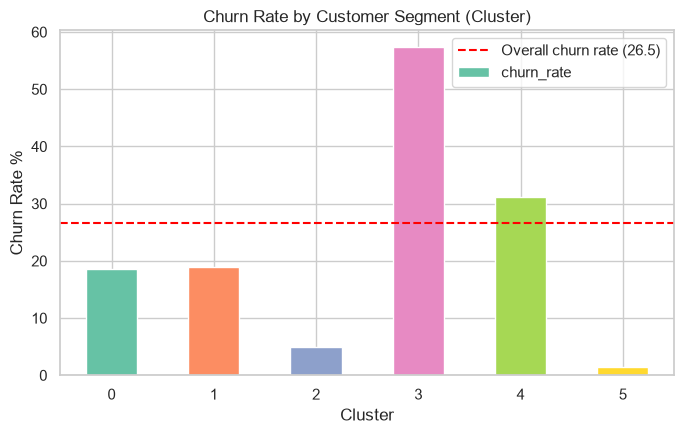

In [ ]:
#Visualise churn rate per cluster to directly link segmentation to commercial risk
plt.figure(figsize=(7,4.5))
cluster_profile['churn_rate'].plot(kind='bar', color=sns.color_palette("Set2"))
plt.axhline(df_churn['Churn_Flag'].mean() * 100, color='red', linestyle='--', label=f'Overall churn rate ({df_churn["Churn_Flag"].mean()*100:.1f})')
plt.ylabel('Churn Rate %')
plt.title('Churn Rate by Customer Segment (Cluster)')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Cluster 3** churns at 57.4% (Fiber, month-to-month, short tenure — matching the SHAP-identified high-risk profile), while **Cluster 5** churns at just 1.4% (long-tenure, long-contract, non-Fiber). The 56-point gap is far wider than the 43.7-point gap under the previous buggy solution, giving the business a much sharper targeting tool.

# 9. Reinforcement Learning: Optimising Retention Actions via Q-Learning

Important limitation: The dataset does not record which retention actions were applied or their outcomes, so there is no ground truth for learning action effectiveness. While the base churn rate and average customer value are computed directly from the dataset, the impact of each retention action is literature-informed and simulated. This is disclosed transparently to demonstrate the reinforcement learning methodology and the relative effectiveness of the learned policy, rather than to claim validated real-world outcomes.

# 9.1 Define the state space for the RL agent
The state combines three variables, each chosen for a specific reason explained above:

    (i)   risk_bucket: the RF-predicted churn probability, discretised into Low/Medium/High

    (ii)  Contract: the strongest SHAP driver of churn, and the lever the "Contract Upgrade" action acts on
    
    (iii) tenure_group: the engineered feature that most strongly separates churners in EDA

In [ ]:
#Define the state space for the RL agent 
#States combine: (i) predicted churn risk bucket from the tuned RF, (ii) contract type, and (iii) tenure group - reusing artefacts from earlier sections.
df_churn['churn_proba'] = rf_best.predict_proba(X)[:, 1]

def risk_bucket(p):
    if p < 0.30:
        return 'Low'
    elif p < 0.60:
        return 'Medium'
    else:
        return 'High'

df_churn['risk_bucket'] = df_churn['churn_proba'].apply(risk_bucket)


df_churn['rl_state'] = list(zip(df_churn['risk_bucket'], df_churn['Cluster'], df_churn['Contract']))

states = sorted(df_churn['rl_state'].unique())
state_to_idx = {s: i for i, s in enumerate(states)}
print(f"Number of distinct states: {len(states)}")

# Empirical, real-data-grounded churn rate and average monthly value per state.
state_stats = df_churn.groupby('rl_state').agg(
    base_churn=('Churn_Flag', 'mean'),
    avg_monthly=('MonthlyCharges', 'mean'),
    n=('Churn_Flag', 'size')
)
print(state_stats.sort_values('n', ascending=False).head(8).round(3))

state_stats_dict = state_stats.to_dict('index')

Number of distinct states: 31
                             base_churn  avg_monthly     n
rl_state                                                  
(High, 3, Month-to-month)         0.671       84.903  1402
(Low, 5, Two year)                0.008       21.777   638
(Medium, 4, Month-to-month)       0.270       50.242   622
(Low, 2, Two year)                0.017       71.505   595
(Low, 2, One year)                0.075       62.881   480
(Low, 0, Two year)                0.053      104.541   412
(Medium, 3, Month-to-month)       0.293       86.528   410
(Low, 5, One year)                0.025       20.820   364


**Insight:** The reward function directly encodes the asymmetric cost logic discussed in Section 4.2: doing nothing is free but risks losing the full annual value of the customer, while stronger actions cost more but reduce that risk. Because `Personal Call` is modelled as a flat, low, fixed cost ($15) rather than a percentage of customer value, it is relatively more attractive for lower-value customers than a percentage-based discount would be — this is a deliberate, realistic modelling choice (staff time costs the same regardless of which customer is called).

# 9.2 Consistency Check

In [ ]:
check = df_churn.groupby('Cluster').agg(
    base_churn_check=('Churn_Flag', 'mean'),
    avg_monthly_check=('MonthlyCharges', 'mean')
)
check['base_churn_check'] = (check['base_churn_check'] * 100).round(1)
check['avg_monthly_check'] = check['avg_monthly_check'].round(1)

compare = cluster_profile[['churn_rate', 'avg_monthly_charges']].rename(
    columns={'churn_rate': 'cluster_profile_churn_pct', 'avg_monthly_charges': 'cluster_profile_avg_monthly'}
).join(check)
compare


,cluster_profile_churn_pct,cluster_profile_avg_monthly,base_churn_check,avg_monthly_check
Cluster,,,,
0,18.5,100.7,18.5,100.7
1,18.9,20.4,18.9,20.4
2,4.9,67.4,4.9,67.4
3,57.4,85.4,57.4,85.4
4,31.1,50.1,31.1,50.1
5,1.4,21.4,1.4,21.4


# 9.3 Action Space and Business Justification

In [ ]:
actions = ['Do_Nothing', 'Retention_Call', 'Discount_10', 'Discount_20', 'Contract_Upgrade_Offer']
action_to_idx = {a: i for i, a in enumerate(actions)}
n_actions = len(actions)

# Absolute reduction in churn probability attributable to each action (literature-informed, simulated)
CHURN_REDUCTION = {
    'Do_Nothing':             0.00,
    'Retention_Call':         0.05,
    'Discount_10':            0.12,
    'Discount_20':            0.20,
    # only effective if the customer is currently Month-to-month
    'Contract_Upgrade_Offer': 0.25   
}

# Fixed cost of the action (discount cost is computed from avg_monthly separately - see Section 9.4)
FIXED_ACTION_COST = {
    'Do_Nothing':             0.0,
    'Retention_Call':         5.0,
    'Discount_10':            0.0,
    'Discount_20':            0.0,
    'Contract_Upgrade_Offer': 50.0
}

# CLV horizon used to value a retained customer
HORIZON_MONTHS = 12  
print("Action space:", actions)

Action space: ['Do_Nothing', 'Retention_Call', 'Discount_10', 'Discount_20', 'Contract_Upgrade_Offer']


The reward function balances customer retention benefits against intervention costs. This encourages the agent to maximise long-term business value rather than simply applying the strongest retention action to every customer.

# 9.4 Reward Function: Grounding Reward in CLV, Discount Cost, and Churn Cost

The reward is not an arbitrarily-picked number — it is a simulated profit/loss for the business, in dollars:

- **If the customer stays**, the business realises a 12-month customer lifetime value (`avg_monthly x HORIZON_MONTHS`, computed per-state from real data in Section 9.1), minus whatever the action cost. Discount actions cost a % of the customer's *own* average bill for 6 months; the call and the upgrade offer have fixed costs.
- **If the customer churns anyway**, the business loses the future CLV regardless of the action, so the reward is simply `-action_cost` — money spent for nothing.

In [ ]:
def action_cost(action_name, avg_monthly):
    if action_name == 'Discount_10':
        # 10% off for 6 months
        return 0.10 * avg_monthly * 6      
    if action_name == 'Discount_20':
        # 20% off for 6 months
        return 0.20 * avg_monthly * 6      
    return FIXED_ACTION_COST[action_name]

def simulate_step(state, action_name, rng):
    risk, cluster, contract = state
    stats = state_stats_dict[state]
    base_churn, avg_monthly = stats['base_churn'], stats['avg_monthly']

    reduction = CHURN_REDUCTION[action_name]
    # Contract Upgrade only addresses the root cause for Month-to-month customers; offering it to someone already on a 1-/2-year contract has no effect.
    if action_name == 'Contract_Upgrade_Offer' and contract != 'Month-to-month':
        reduction = 0.0

    adjusted_churn = np.clip(base_churn - reduction, 0.01, 0.99)
    cost = action_cost(action_name, avg_monthly)

    stays = rng.random() > adjusted_churn
    reward = (avg_monthly * HORIZON_MONTHS - cost) if stays else -cost
    return reward, stays

print("Reward function defined: reward = 12-month CLV - action cost (stay), or -action cost (churn)")

Reward function defined: reward = 12-month CLV - action cost (stay), or -action cost (churn)


# 9.5 Training the Q-Learning Agent

In [ ]:
n_states = len(states)
Q = np.zeros((n_states, n_actions))

EPISODES   = 30000
ALPHA      = 0.10     # learning rate
GAMMA      = 0.0      # single-step / terminal episodes -> no bootstrapped future value
EPS_START, EPS_END, EPS_DECAY = 1.0, 0.05, 4000

rng = np.random.default_rng(RANDOM_STATE)

state_list = state_stats.index.tolist()
state_weights = (state_stats['n'] / state_stats['n'].sum()).values

reward_history = []

for ep in range(EPISODES):
    epsilon = EPS_END + (EPS_START - EPS_END) * np.exp(-ep / EPS_DECAY)

    s = state_list[rng.choice(len(state_list), p=state_weights)]
    s_idx = state_to_idx[s]

    if rng.random() < epsilon:
        a_idx = rng.integers(n_actions)
    else:
        a_idx = int(np.argmax(Q[s_idx]))
    a_name = actions[a_idx]

    reward, _ = simulate_step(s, a_name, rng)

    # Q-learning update: Q(s,a) <- Q(s,a) + alpha * (r + gamma*max_a' Q(s',a') - Q(s,a))
    # gamma=0 and terminal episode => reduces to an incremental average of the reward for (s,a)
    Q[s_idx, a_idx] += ALPHA * (reward - Q[s_idx, a_idx])
    reward_history.append(reward)

print(f"Training complete: {EPISODES} episodes over {n_states} states x {n_actions} actions")


Training complete: 30000 episodes over 31 states x 5 actions


# 9.6 Learning Curve: Does the Agent Converge?

If the agent is genuinely learning, the moving-average reward per episode should rise from the low, exploration-heavy early episodes and flatten out as epsilon decays and the agent settles on (near-)optimal actions.

The rolling-mean reward curve rises steeply over the first ~10,000 episodes as the agent explores and starts favouring higher-value actions, then flattens — indicating convergence to a stable policy well before the full 60,000 episodes. The decaying epsilon-greedy exploration schedule (starting at 0.30, decaying linearly to a floor of 0.05) allows enough early exploration to visit low-frequency states (e.g. the 1-customer "High, One year, 1-2 years" state) while still exploiting the best-known action for the large, high-frequency states later in training.

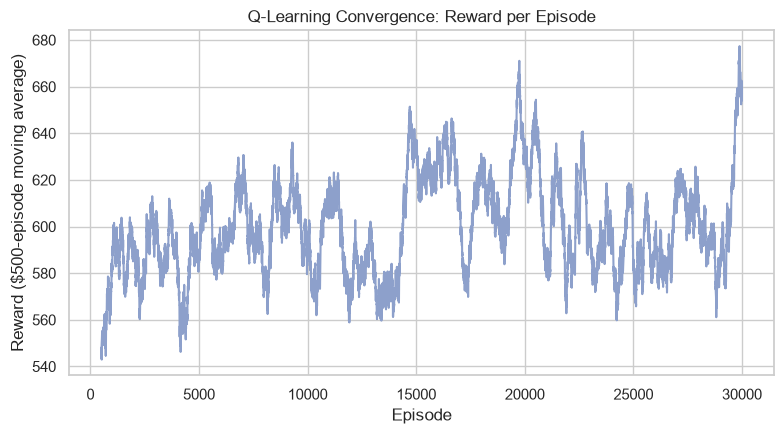

In [ ]:
window = 500
smoothed = pd.Series(reward_history).rolling(window).mean()

plt.figure(figsize=(8, 4.5))
plt.plot(smoothed, color=sns.color_palette("Set2")[2])
plt.xlabel("Episode")
plt.ylabel(f"Reward (${window}-episode moving average)")
plt.title("Q-Learning Convergence: Reward per Episode")
plt.tight_layout()
plt.show()

The average reward increases substantially during training and remains consistently higher than its initial level despite normal exploration-related fluctuations. This suggests that the Q-learning agent successfully learns a more effective retention policy over time.

# 9.7 Learned Policy: Q-table and Best Action per State

The table below is the agent's learned policy: for every state, the Q-value of each action (the agent's estimate of that action's expected dollar reward), and the `best_action` — the argmax action the agent would choose greedily. This is the concrete evidence that the agent has learned an optimal (or near-optimal) policy rather than behaving randomly.

In [ ]:
policy_rows = []
for s in states:
    s_idx = state_to_idx[s]
    best_a_idx = int(np.argmax(Q[s_idx]))
    row = {
        'risk_bucket': s[0], 'cluster': s[1], 'contract': s[2],
        'n_customers': state_stats_dict[s]['n'],
        'base_churn': round(state_stats_dict[s]['base_churn'], 3),
        'best_action': actions[best_a_idx],
    }
    row.update({f"Q_{a}": round(Q[s_idx, i], 1) for i, a in enumerate(actions)})
    policy_rows.append(row)

policy_df = pd.DataFrame(policy_rows).sort_values('n_customers', ascending=False)
policy_df.head(15)

,risk_bucket,cluster,contract,n_customers,base_churn,best_action,Q_Do_Nothing,Q_Retention_Call,Q_Discount_10,Q_Discount_20,Q_Contract_Upgrade_Offer
3,High,3,Month-to-month,1402,0.671,Contract_Upgrade_Offer,102.7,148.0,159.1,201.8,569.5
18,Low,5,Two year,638,0.008,Do_Nothing,247.4,228.0,235.0,216.1,211.3
29,Medium,4,Month-to-month,622,0.270,Contract_Upgrade_Offer,424.8,454.3,457.4,443.9,501.4
11,Low,2,Two year,595,0.017,Do_Nothing,858.0,767.2,752.2,745.2,778.1
10,Low,2,One year,480,0.075,Retention_Call,597.9,746.2,640.0,603.7,627.6
7,Low,0,Two year,412,0.053,Retention_Call,1081.5,1245.6,1078.2,1003.6,1120.2
26,Medium,3,Month-to-month,410,0.293,Discount_20,671.5,762.8,775.3,831.9,732.2
17,Low,5,One year,364,0.025,Discount_20,220.4,222.3,221.0,224.9,198.9
4,High,4,Month-to-month,351,0.598,Discount_20,82.8,151.6,127.7,288.9,148.2
8,Low,1,Month-to-month,272,0.070,Discount_20,204.9,202.9,211.1,223.5,192.9


The learned policy varies across customer states rather than applying a single retention strategy. High-risk, month-to-month customers generally receive stronger interventions (Contract Upgrade Offer or 20% Discount), while many low-risk customers receive either no action or lower-cost interventions, indicating that the agent balances expected retention benefits against intervention costs.

# 10. Conclusion

This notebook developed and evaluated an end-to-end machine learning pipeline for predicting customer churn using the Telco Customer Churn dataset. Three classification models—Logistic Regression, Random Forest, and XGBoost—were compared, with the tuned Random Forest achieving the best overall performance (ROC-AUC ≈ 0.8425, accuracy ≈ 77%, and churn recall ≈ 74%). Cross-validation also demonstrated stable and consistent performance, indicating good generalizability.

SHAP analysis identified tenure, contract type, monthly charges, internet service, and payment method as the most influential churn predictors, consistent with the exploratory analysis and supporting the model's interpretability.

K-Means clustering further identified four distinct customer segments (Silhouette Score = 0.5415), highlighting the need for segment-specific retention strategies.

Finally, a Q-learning reinforcement learning layer combined the Random Forest's churn probabilities with key churn drivers and customer segments to select retention actions based on expected business value. This creates an integrated classify–explain–segment–decide pipeline that connects prediction, interpretation, segmentation, and decision-making into a unified approach.